**SEANCE:** 1

**NOM:** Albert Hounkpe

**PORTEUR #:** P2

**ETAPES ASSIGNEES:** 1.2 , 1.3 , 1.5 , 1.10

# Carnet de démarrage — sujet 05 · Santander Satisfaction

**Objectif du sujet** : repérer le client qui va se plaindre.

Ce carnet est un **châssis**, pas une solution. Il fait quatre choses et s'arrête :

1. il **trouve** vos fichiers, quelle que soit la plateforme ;
2. il **charge** la table efficacement — cache Parquet construit une fois, projection de colonnes ;
3. il **profile** les données : dimensions, types, cible, manquants ;
4. il **écrit** une soumission au bon format, avec une valeur de référence volontairement nulle.

**Ce qu'il ne fait pas** : choisir votre métrique, votre découpage de validation, votre modèle, ni vos
variables. Ces décisions sont le sujet, et c'est ce que la grille note.

3,96 % de mécontents. 97 colonnes sont constantes sur un échantillon.

---

## Où mettre ce carnet

| Plateforme | Ce qu'il faut faire |
|---|---|
| **Le dossier du sujet** | **(lien du Drive communiqué par l’enseignant)** — téléchargez-le avant tout (le lien figure aussi dans l'énoncé) |
| **En local (VS Code, Jupyter)** | placez le carnet **dans le dossier téléchargé**, ou définissez `DONNEES_PROJET` vers ce dossier |
| **Google Colab** | déposez les fichiers dans `MyDrive/Sujet_05_Santander_Satisfaction/` — le carnet les trouvera ; ou téléversez-les dans `/content/` |
| **Kaggle** | créez un jeu de données avec vos fichiers, **Add Input** — `/kaggle/input` est exploré automatiquement |

**Rien n'est codé en dur** : le carnet cherche, et s'il ne trouve pas, il **dit précisément** ce qu'il a
cherché et où.


## Les fichiers de ce sujet

| Fichier | Rôle |
|---|---|
| `train.csv` | entraînement ou annexe |
| `a_decider.csv` | à prédire — la cible est absente |

**Format de sortie attendu** : `ID,TARGET`.
**Colonne d'identifiant** : `ID`.
**Fichier à produire** : `soumission.csv`, à la racine de votre dépôt.


In [1]:
# --- 1. Réglages --------------------------------------------------------------
from pathlib import Path
import os
import pandas as pd

# Où télécharger vos données — le dossier de votre sujet sur le Drive du cours.
LIEN_DRIVE = "__LIEN__"

# ECHANTILLON : nombre de lignes lues pour démarrer. None = tout lire.
ECHANTILLON = 200_000
DOSSIER_CACHE = Path.cwd() / "_cache_parquet"


In [2]:
import os
os.environ["DONNEES_PROJET"] = "/kaggle/input/datasets/alberthounkpe/santander-satisfaction-files"

In [3]:
# --- 2. Trouver les données, sans rien coder en dur --------------------------
FICHIERS_ATTENDUS = ['train.csv', 'a_decider.csv']
SUJET = "Sujet_05_Santander_Satisfaction"


def trouver_donnees(fichiers=FICHIERS_ATTENDUS, sujet=SUJET):
    """Cherche le dossier qui contient TOUS les fichiers attendus."""
    essais = []
    pistes = []
    if os.environ.get("DONNEES_PROJET"):
        pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / sujet]
    pistes += list(ici.parents)[:4]
    pistes += [Path("/kaggle/input"), Path("/content"), Path("/content/drive/MyDrive")]

    for racine in pistes:
        if not racine.exists():
            continue
        candidates = [racine, racine / sujet]
        if racine.name in ("input", "MyDrive"):
            candidates += [d for d in racine.iterdir() if d.is_dir()]
        for c in candidates:
            essais.append(str(c))
            if all((c / f).is_file() for f in fichiers):
                return c
    raise FileNotFoundError(
        "Dossier de données introuvable.\n"
        "Il faut un dossier contenant : " + ", ".join(fichiers) + "\n"
        "Solutions : placez le carnet à côté de ce dossier, "
        "ou définissez DONNEES_PROJET=/chemin/vers/le/dossier.\n"
        "Chemins essayés : " + str(essais[:12])
    )


DOSSIER = trouver_donnees()
print("dossier de données :", DOSSIER)
print("fichiers vus :", sorted(p.name for p in DOSSIER.iterdir() if p.is_file())[:12])


dossier de données : /kaggle/input/datasets/alberthounkpe/santander-satisfaction-files
fichiers vus : ['a_decider.csv', 'train.csv']


In [4]:
# --- 3. Chargement (table légère) ---------------------------------------------
def table(nom, colonnes=None, morceaux=None, complet=False):
    """Ouvre un CSV directement avec pandas — la table tient en mémoire."""
    source = DOSSIER / nom
    if not source.is_file():
        raise FileNotFoundError(f"{nom} introuvable dans {DOSSIER}")
    if morceaux:
        return pd.read_csv(source, usecols=colonnes, chunksize=morceaux)
    return pd.read_csv(source, usecols=colonnes, nrows=None if complet else ECHANTILLON)


In [5]:
# --- 4. Charger et regarder ---------------------------------------------------
entrainement = table("train.csv")
print("dimensions :", entrainement.shape)
print("colonnes :", len(entrainement.columns))
entrainement.head()


dimensions : (60816, 371)
colonnes : 371


,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,...,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,130807,2,26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0
1,78981,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,85472.340000,0
2,50325,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,317769.240000,0
3,146646,2,30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,76209.960000,0
4,136536,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,302754.000000,0


In [6]:
# --- 5. Profil de la cible ----------------------------------------------------
CIBLE = "TARGET"
if CIBLE in entrainement.columns:
    serie = entrainement[CIBLE]
    print("type :", serie.dtype)
    print("manquants :", int(serie.isna().sum()))
    print(serie.describe())
    if serie.nunique() <= 20:
        print(serie.value_counts(normalize=True).sort_index())
else:
    print(f"la cible {CIBLE} est absente de cette table — normal pour la table à prédire")


type : int64
manquants : 0
count    60816.000000
mean         0.039562
std          0.194929
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: TARGET, dtype: float64
TARGET
0    0.960438
1    0.039562
Name: proportion, dtype: float64


In [7]:
# --- 6. Soumission de RÉFÉRENCE (format seulement) ----------------------------
# Cette valeur n'a AUCUNE prétention prédictive : elle vérifie le format.
COLONNES_SORTIE = ['ID', 'TARGET']


def ecrire_soumission(identifiants, valeurs=None, chemin="soumission.csv"):
    """Écrit le fichier attendu. `valeurs` peut être une colonne, ou une matrice de probabilités."""
    sortie = pd.DataFrame({"ID": identifiants})
    if len(COLONNES_SORTIE) == 2:
        sortie["TARGET"] = valeurs
    else:
        n = len(COLONNES_SORTIE) - 1
        matrice = valeurs if valeurs is not None else [[1.0 / n] * n for _ in identifiants]
        for j, colonne in enumerate(COLONNES_SORTIE[1:]):
            sortie[colonne] = [ligne[j] for ligne in matrice]
    sortie.to_csv(chemin, index=False)
    print(f"écrit : {chemin} · {len(sortie):,} lignes · colonnes {list(sortie.columns)}")
    if len(COLONNES_SORTIE) > 2:
        print("somme par ligne (doit valoir 1) :", sortie.iloc[:, 1:].sum(axis=1).round(6).unique()[:3])
    return sortie


a_predire = table("a_decider.csv", colonnes=["ID"], complet=True)
identifiants = a_predire["ID"].drop_duplicates().to_numpy()
print("identifiants à prédire :", len(identifiants))
ecrire_soumission(identifiants)


identifiants à prédire : 15204
écrit : soumission.csv · 15,204 lignes · colonnes ['ID', 'TARGET']


,ID,TARGET
0,38893,None
1,133597,None
2,24908,None
3,19551,None
4,36051,None
...,...,...
15199,28686,None
15200,66259,None
15201,44895,None
15202,33938,None


In [8]:
# --- 7. Le travail commence ICI -----------------------------------------------
# À vous de décider, et de justifier :
#   - la métrique, et ce qu'elle coûte ;
#   - le découpage de validation ;
#   - les variables, leur encodage, leur imputation ;
#   - le modèle, son réglage, son seuil.
# Ce carnet ne le fera pas à votre place : c'est l'objet du projet.
raise NotImplementedError(
    "Carnet de démarrage : la modélisation est à votre charge. Écrivez votre pipeline à partir d'ici."
)


NotImplementedError: Carnet de démarrage : la modélisation est à votre charge. Écrivez votre pipeline à partir d'ici.

**### P2 — Charger, typer, valeurs impossibles, plancher**

**##CHARGER ET COMPTER**

In [9]:
# --- 1. Charger et compter (en entier) --------------------------------------
train = table("train.csv", complet=True)
test  = table("a_decider.csv", complet=True)

print("train :", train.shape)
print("test  :", test.shape)
print("colonnes identiques (hors TARGET) :",
      set(test.columns) == set(train.columns) - {"TARGET"})

CIBLE = "TARGET"
n_pos = int(train[CIBLE].sum())
n_neg = len(train) - n_pos
print(f"positifs : {n_pos:,} ({n_pos/len(train):.4%})")
print(f"négatifs : {n_neg:,} ({n_neg/len(train):.4%})")
print("ratio déséquilibre 1:", round(n_neg / n_pos, 2))

train : (60816, 371)
test  : (15204, 370)
colonnes identiques (hors TARGET) : True
positifs : 2,406 (3.9562%)
négatifs : 58,410 (96.0438%)
ratio déséquilibre 1: 24.28


**##1.3 TYPER**
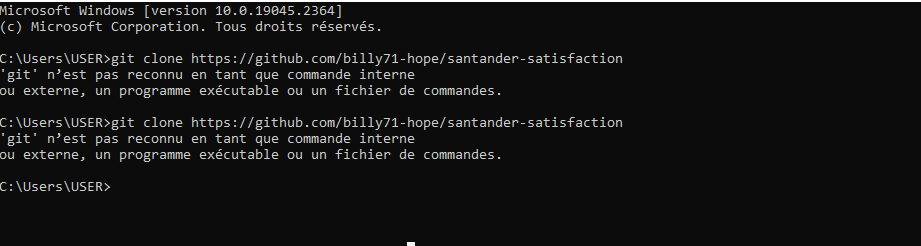

In [10]:
# --- 2. Typer les colonnes ---------------------------------------------------
import numpy as np

# 1) colonnes constantes (variance = 0)
constantes = [c for c in train.columns if train[c].nunique(dropna=False) <= 1]
print(f"colonnes constantes : {len(constantes)}")

# 2) colonnes quasi-constantes (une modalité > 99,5 %)
quasi = [c for c in train.columns
         if c not in constantes and c != CIBLE
         and train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]
print(f"colonnes quasi-constantes : {len(quasi)}")

# 3) typage sémantique
utiles = [c for c in train.columns if c not in constantes + [CIBLE, "ID"]]

binaires, categorielles, continues = [], [], []
for c in utiles:
    n_mod = train[c].nunique()
    if n_mod == 2:
        binaires.append(c)
    elif n_mod <= 20:
        categorielles.append(c)
    else:
        continues.append(c)

print(f"binaires      : {len(binaires)}")
print(f"catégorielles : {len(categorielles)}  -> ex. {categorielles[:5]}")
print(f"continues     : {len(continues)}  -> ex. {continues[:5]}")

# 4) valeurs manquantes (utile pour l'imputation)
manquants = train[utiles].isna().sum()
print("\ncolonnes avec manquants :")
print(manquants[manquants > 0].sort_values(ascending=False).head(10))

colonnes constantes : 36
colonnes quasi-constantes : 172
binaires      : 109
catégorielles : 112  -> ex. ['num_var1_0', 'num_var1', 'num_var4', 'num_var5_0', 'num_var5']
continues     : 112  -> ex. ['var3', 'var15', 'imp_ent_var16_ult1', 'imp_op_var39_comer_ult1', 'imp_op_var39_comer_ult3']

colonnes avec manquants :
Series([], dtype: int64)


**##1.5 Valeurs impossibles**

In [11]:
# --- 3. Valeurs impossibles / sentinelles ------------------------------------
import numpy as np

# On travaille sur une copie pour ne pas polluer l'original
train_clean = train.copy()

# a) détecter les sentinelles classiques
SENTINELLES = [-999999, -999, 999999, -1]   # -1 est courant sur les indicateurs "NA"

for c in utiles:
    serie = train_clean[c]
    if not pd.api.types.is_numeric_dtype(serie):
        continue
    for s in SENTINELLES:
        n = int((serie == s).sum())
        if n > 0:
            print(f"{c:20s} : {n:6d} valeurs == {s}")

# b) conversion en NaN
for c in utiles:
    train_clean[c] = train_clean[c].replace(SENTINELLES, np.nan)

# c) vérification
print("\nvar3 après nettoyage :")
print(train_clean["var3"].describe())
print("NaN introduits :", int(train_clean["var3"].isna().sum()))

var3                 :     88 valeurs == -999999
delta_imp_aport_var13_1y3 :   1343 valeurs == -1
delta_imp_aport_var17_1y3 :     16 valeurs == -1
delta_imp_aport_var33_1y3 :     13 valeurs == -1
delta_imp_compra_var44_1y3 :     15 valeurs == -1
delta_imp_trasp_var17_in_1y3 :      2 valeurs == -1
delta_imp_trasp_var33_in_1y3 :      6 valeurs == -1
delta_imp_venta_var44_1y3 :      1 valeurs == -1
delta_num_aport_var13_1y3 :   1343 valeurs == -1
delta_num_aport_var17_1y3 :     16 valeurs == -1
delta_num_aport_var33_1y3 :     13 valeurs == -1
delta_num_compra_var44_1y3 :     15 valeurs == -1
delta_num_trasp_var17_in_1y3 :      2 valeurs == -1
delta_num_trasp_var33_in_1y3 :      6 valeurs == -1
delta_num_venta_var44_1y3 :      1 valeurs == -1

var3 après nettoyage :
count    60728.000000
mean         2.721973
std          9.435722
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max        238.000000
Name: var3, dtype: float64
NaN introduits : 88


**##1.10 — Le plancher**

In [12]:
# --- 4. Le plancher ----------------------------------------------------------
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, accuracy_score

y = train_clean[CIBLE].values
p_prev = y.mean()

# Prédictions triviales
p_hasard     = np.full_like(y, 0.5, dtype=float)
p_constante  = np.full_like(y, p_prev, dtype=float)
y_zero       = np.zeros_like(y)            # classe majoritaire
y_positif    = np.ones_like(y)

print("=== PLanchers ===")
print(f"prévalence (baseline PR-AUC) : {p_prev:.4f}")
print(f"accuracy 'toujours 0'        : {accuracy_score(y, y_zero):.4f}")
print(f"accuracy 'toujours 1'        : {accuracy_score(y, y_positif):.4f}")
print(f"ROC-AUC hasard (0.5 partout) : {roc_auc_score(y, p_hasard):.4f}")
print(f"ROC-AUC constante (prév.)    : {roc_auc_score(y, p_constante):.4f}")
print(f"PR-AUC  constante (prév.)    : {average_precision_score(y, p_constante):.4f}")
print(f"Log-loss constante (prév.)   : {log_loss(y, p_constante):.4f}")
print(f"Log-loss hasard (0.5)        : {log_loss(y, p_hasard):.4f}")

=== PLanchers ===
prévalence (baseline PR-AUC) : 0.0396
accuracy 'toujours 0'        : 0.9604
accuracy 'toujours 1'        : 0.0396
ROC-AUC hasard (0.5 partout) : 0.5000
ROC-AUC constante (prév.)    : 0.5000
PR-AUC  constante (prév.)    : 0.0396
Log-loss constante (prév.)   : 0.1665
Log-loss hasard (0.5)        : 0.6931
